# 02 · Error analysis: LightGBM on FD001

> **Data-use rule.** Every analysis here that could lead to a model change uses **only the 5-fold
> out-of-fold (OOF) cross-validation predictions** of the primary model on the training engines.
> The official test predictions (`reports/test_predictions_fd001.csv`) appear only in section 5.
> They are **described, never used to change anything**: the test set was evaluated once, and
> any change motivated by it would make that result optimistic. The test file is read only to
> count each engine's observed cycles.

The primary model is LightGBM on causal window features (windows 10 and 30), with the training
target capped at 125 ([ADR 0002](../docs/adr/0002-model-choice.md)). The OOF predictions below
are recomputed with exactly the frozen settings.

**Sign convention:** error = predicted RUL − true RUL. A **positive error is late**: the model
says more life remains than actually does, which is the dangerous direction for maintenance.
A negative error is early, which is costly but safe.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from predmaint.data.download import PROJECT_ROOT
from predmaint.data.load import add_rul, load_test, load_train
from predmaint.features.selection import DEFAULT_RUL_CAP
from predmaint.models.gbdt import make_lgbm
from predmaint.training.cv import cross_validate
from predmaint.training.run_cv import DEFAULT_WINDOWS, N_SPLITS, SEED, build_features

BLUE, RED, GRAY, INK = "#2a78d6", "#e34948", "#8a8984", "#52514e"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1-3
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "xtick.color": INK,
        "ytick.color": INK,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
    }
)
pd.set_option("display.precision", 2)


def rmse(e: pd.Series) -> float:
    return float(np.sqrt(np.mean(np.square(e))))


def label(interval: pd.Interval) -> str:
    return f"{max(interval.left, 0):g}–{interval.right:g}"


train = add_rul(load_train("FD001"))
data, features = build_features(train, "window", DEFAULT_WINDOWS)
cv = cross_validate(
    make_lgbm, data, cap=DEFAULT_RUL_CAP, features=features, n_splits=N_SPLITS, seed=SEED
)
oof = cv.oof.copy()
oof["error"] = oof["pred"] - oof["rul"]  # > 0: late
oof["lifetime"] = oof.groupby("unit")["cycle"].transform("max")
scored = oof[oof["scored"]].copy()  # true RUL <= 150: the evaluation population
print("CV summary (must match ADR 0002: RMSE 16.51 ± 1.06):")
print(cv.summary().round(2))
print(f"OOF rows: {len(oof)}, of which scored (true RUL <= 150): {len(scored)}")

CV summary (must match ADR 0002: RMSE 16.51 ± 1.06):
       rmse    mae
mean  16.51  12.36
std    1.06   0.90
OOF rows: 20631, of which scored (true RUL <= 150): 15024


## 1. Error vs true RUL: late and early errors

In [2]:
BUCKETS = [0, 25, 50, 75, 100, 125, 150]
scored["rul_bucket"] = pd.cut(scored["rul"], BUCKETS, include_lowest=True)


def error_profile(e: pd.Series) -> pd.Series:
    return pd.Series(
        {
            "rows": len(e),
            "rmse": rmse(e),
            "bias": e.mean(),
            "late %": 100 * (e > 0).mean(),
            "late >20 %": 100 * (e > 20).mean(),
            "early >20 %": 100 * (e < -20).mean(),
            "mean late": e[e > 0].mean(),
            "mean early": -e[e < 0].mean(),
        }
    )


by_rul = scored.groupby("rul_bucket", observed=True)["error"].apply(error_profile).unstack()
by_rul

,rows,rmse,bias,late %,late >20 %,early >20 %,mean late,mean early
rul_bucket,,,,,,,,
"(-0.001, 25.0]",2600.0,3.89,1.26,62.04,0.04,0.00,3.35,2.16
"(25.0, 50.0]",2500.0,10.50,3.75,61.88,6.72,0.12,9.13,4.98
"(50.0, 75.0]",2500.0,18.74,9.24,67.64,25.64,1.60,17.85,8.77
"(75.0, 100.0]",2500.0,18.47,8.65,71.12,27.32,5.92,17.05,12.06
"(100.0, 125.0]",2500.0,14.19,-3.92,41.24,1.52,12.44,8.78,12.83
"(125.0, 150.0]",2424.0,25.34,-22.74,0.17,0.00,57.51,1.26,22.78


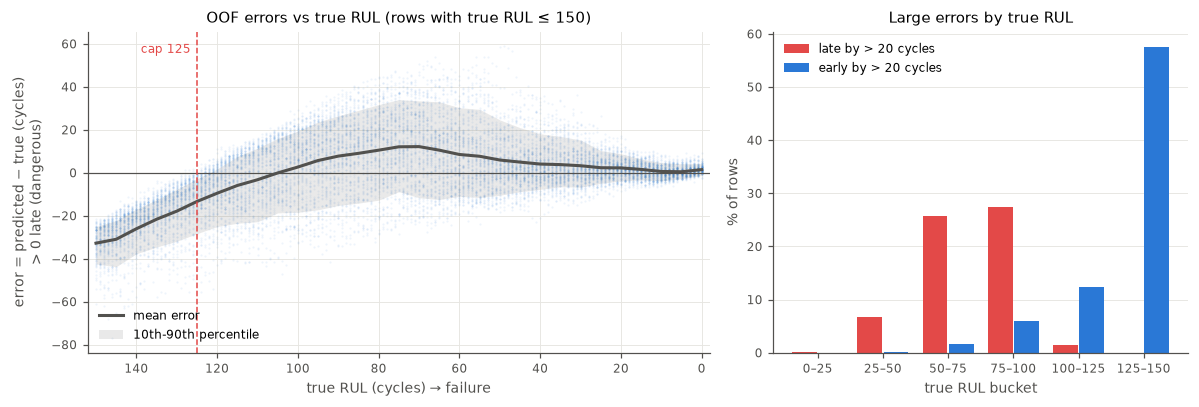

In [3]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 2]})
ax.scatter(scored["rul"], scored["error"], s=2, color=BLUE, alpha=0.08, linewidths=0)
binned = scored.groupby(scored["rul"] // 5 * 5)["error"]
ax.plot(binned.mean().index, binned.mean(), color=INK, linewidth=2, label="mean error")
ax.fill_between(
    binned.quantile(0.1).index,
    binned.quantile(0.1),
    binned.quantile(0.9),
    color=INK,
    alpha=0.12,
    linewidth=0,
    label="10th-90th percentile",
)
ax.axhline(0, color=INK, linewidth=0.8)
ax.axvline(DEFAULT_RUL_CAP, color=RED, linestyle="--", linewidth=1)
ax.annotate(
    "cap 125",
    xy=(DEFAULT_RUL_CAP, ax.get_ylim()[1] * 0.85),
    xytext=(-4, 0),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    color=RED,
)
ax.set_xlim(152, -2)
ax.set_xlabel("true RUL (cycles) → failure")
ax.set_ylabel("error = predicted − true (cycles)\n> 0 late (dangerous)")
ax.set_title("OOF errors vs true RUL (rows with true RUL ≤ 150)")
ax.legend(fontsize=8, loc="lower left", frameon=False)

x = np.arange(len(by_rul))
ax2.bar(x - 0.2, by_rul["late >20 %"], width=0.38, color=RED, label="late by > 20 cycles")
ax2.bar(x + 0.2, by_rul["early >20 %"], width=0.38, color=BLUE, label="early by > 20 cycles")
ax2.set_xticks(x, [label(b) for b in by_rul.index])
ax2.set_xlabel("true RUL bucket")
ax2.set_ylabel("% of rows")
ax2.set_title("Large errors by true RUL")
ax2.legend(fontsize=8, frameon=False)
ax2.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

**Findings**

- **Errors depend strongly on true RUL.**
  - Near failure (true RUL 0–25), the model is accurate: RMSE 3.9, bias +1.3.
  - RMSE rises to 18.7 at 50–75 and 18.5 at 75–100.
- **Mid-life is where the dangerous late errors are.**
  - At true RUL 50–75 and 75–100, the bias is +9.2 and +8.7 cycles.
  - 25.6% and 27.3% of rows are late by more than 20 cycles.
  - The mean late error is 17.9 and 17.1 cycles.
  - The mean-error curve peaks at about +12 cycles around true RUL 70–75.
- **Beyond about 100 the errors flip to early.**
  - At 100–125 the bias is −3.9.
  - At 125–150 the bias is −22.7: 57.5% of rows are early by more than 20 cycles, and only 0.17% are late.
- *Interpretation (not tested here):* in mid-life the sensors have changed little (notebook 01 found about 10% of the total sensor change by RUL 130). The model therefore still predicts values close to the 125 cap, which is late for an engine that will actually fail sooner.

## 2. Error vs history length

History length is the number of cycles of an engine seen so far, i.e. the cycle number. It is
confounded with true RUL, because an early cycle usually means a high RUL. So errors are compared
**within the same true-RUL band**. Window features need 10 or 30 cycles to fill; before that,
the windows shrink.

In [4]:
HIST = [0, 30, 60, 100, 150, 400]
BANDS = [0, 50, 100, 150]
scored["history"] = pd.cut(scored["cycle"], HIST)
scored["rul_band"] = pd.cut(scored["rul"], BANDS, include_lowest=True)
grid = scored.groupby(["history", "rul_band"], observed=True)["error"]
print("RMSE (cycles) by history length (rows) and true-RUL band (columns):")
print(grid.apply(rmse).unstack().round(1).to_string())
print("\nMean error (bias; > 0 = late):")
print(grid.mean().unstack().round(1).to_string())
print("\nRows per cell:")
print(grid.size().unstack().to_string())

RMSE (cycles) by history length (rows) and true-RUL band (columns):
rul_band    (-0.001, 50.0]  (50.0, 100.0]  (100.0, 150.0]
history                                                  
(0, 30]                NaN           16.9            20.8
(30, 60]               NaN           22.1            20.1
(60, 100]             23.9           23.8            18.4
(100, 150]            10.7           17.6            22.0
(150, 400]             5.8           14.1            25.1

Mean error (bias; > 0 = late):
rul_band    (-0.001, 50.0]  (50.0, 100.0]  (100.0, 150.0]
history                                                  
(0, 30]                NaN           16.4           -15.9
(30, 60]               NaN           18.0           -12.4
(60, 100]             18.8           19.9           -10.4
(100, 150]             6.3            9.7           -14.2
(150, 400]             0.8           -3.2           -20.9

Rows per cell:
rul_band    (-0.001, 50.0]  (50.0, 100.0]  (100.0, 150.0]
history       

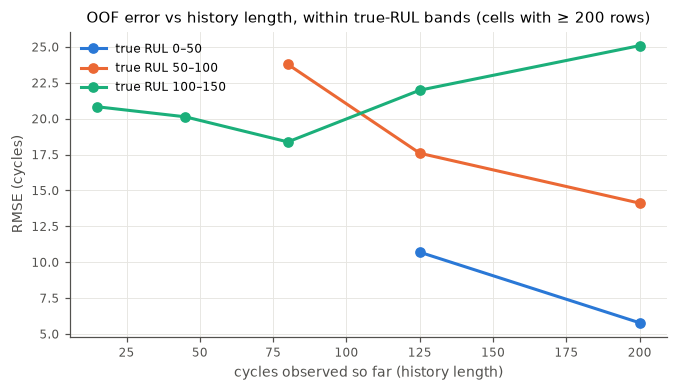

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
cell = grid.apply(rmse).unstack()
mid = [(i.left + min(i.right, 250)) / 2 for i in cell.index]
for color, band in zip(SERIES, cell.columns, strict=True):
    counts = grid.size().unstack()[band]
    keep = counts >= 200  # hide cells with too few rows to estimate RMSE
    ax.plot(
        np.array(mid)[keep],
        cell[band][keep],
        marker="o",
        color=color,
        linewidth=2,
        label=f"true RUL {label(band)}",
    )
ax.set_xlabel("cycles observed so far (history length)")
ax.set_ylabel("RMSE (cycles)")
ax.set_title("OOF error vs history length, within true-RUL bands (cells with ≥ 200 rows)")
ax.legend(fontsize=8, frameon=False)
plt.show()

**Findings**

- **Within the same true-RUL band, a short history means later predictions.**
  - At true RUL 50–100, rows seen after 30–100 cycles have a bias of +18.0 to +19.9 and RMSE up to 23.8.
  - Rows seen after more than 150 cycles have a bias of −3.2 and RMSE 14.1.
  - At true RUL 0–50, the 60–100-cycle cell has a bias of +18.8 and RMSE 23.9, though with only 76 rows; after more than 150 cycles, it's +0.8 and 5.8.
- **At true RUL 100–150, the bias is negative at every history length** (−10.4 to −20.9). That's the cap effect (section 4). The error is highest for the longest histories (RMSE 25.1, bias −20.9).
- **Caveat: this is confounded with lifetime.** For a fixed true RUL, history = lifetime − RUL. A short history therefore means a *short-lived* engine. These data cannot separate "too little history" from "a fast-degrading engine". It's also not a window-filling effect: by 30 cycles both windows are full, and the ≤ 30-cycle cells contain almost only RUL > 100 rows.
- **Why it matters for the test set:** test engines have 31 to 303 cycles of history (median 134), so some sit in the late-prediction cells.

## 3. Worst engines in CV

In [6]:
engines = scored.groupby("unit").agg(
    rmse=("error", rmse),
    bias=("error", "mean"),
    lifetime=("lifetime", "first"),
    fold=("fold", "first"),
)
engines["lifetime pct"] = 100 * engines["lifetime"].rank(pct=True)
worst = engines.sort_values("rmse", ascending=False).head(5)
below_cap = scored["rul"] <= DEFAULT_RUL_CAP
for name, mask in (("≤125", below_cap), (">125", ~below_cap)):
    part = scored[mask & scored["unit"].isin(worst.index)].groupby("unit")["error"]
    worst[f"rmse RUL {name}"] = part.apply(rmse)
    worst[f"bias RUL {name}"] = part.mean()
    worst[f"rows RUL {name}"] = part.size()
typical_unit = int((engines["rmse"] - engines["rmse"].median()).abs().idxmin())
print(
    f"Per-engine RMSE: median {engines['rmse'].median():.1f}, "
    f"90th percentile {engines['rmse'].quantile(0.9):.1f}, max {engines['rmse'].max():.1f}"
)
print(f"Typical engine (median RMSE): unit {typical_unit}\n")
worst

Per-engine RMSE: median 15.6, 90th percentile 21.1, max 25.6
Typical engine (median RMSE): unit 52



,rmse,bias,lifetime,fold,lifetime pct,rmse RUL ≤125,bias RUL ≤125,rows RUL ≤125,rmse RUL >125,bias RUL >125,rows RUL >125
unit,,,,,,,,,,,
92,25.56,-18.70,341,4,99.0,19.08,-13.60,126,45.95,-44.42,25
56,25.56,-21.48,275,1,90.0,21.26,-17.71,126,40.83,-40.46,25
22,24.67,-17.64,202,4,57.0,17.07,-12.02,126,46.99,-45.96,25
86,23.94,-16.79,278,1,92.0,17.07,-11.34,126,44.64,-44.25,25
57,23.59,17.13,137,3,3.5,24.53,19.05,126,6.45,-4.90,11


In [7]:
# Are the worst engines unusual? Compare early-life sensor levels (first 30 cycles) and total
# degradation (last 10 cycles minus first 30) with the fleet, in units of fleet std.
KEY = ["s_11", "s_4", "s_12", "s_7"]  # strongest correlations with RUL (notebook 01)
first = train[train["cycle"] <= 30].groupby("unit")[KEY].mean()
last = train[train["rul"] < 10].groupby("unit")[KEY].mean()
change = last - first
z_first = (first - first.mean()) / first.std()
z_change = (change - change.mean()) / change.std()
unusual = pd.concat(
    {"early-life level z": z_first.loc[worst.index], "degradation z": z_change.loc[worst.index]},
    axis=1,
)
print("z-scores of the worst engines relative to all 100 engines (|z| > 2 is unusual):")
unusual.round(1)

z-scores of the worst engines relative to all 100 engines (|z| > 2 is unusual):


early-life level z                degradation z               
                   s_11  s_4 s_12  s_7          s_11  s_4 s_12  s_7
unit                                                               
92                 -0.2  0.2  0.3  0.4          -0.1  0.1 -0.2 -0.8
56                  1.4  1.1 -1.3 -1.4          -1.8 -0.9  1.3  1.7
22                  1.7  1.8 -2.0 -1.4          -1.2 -1.8  1.0  1.2
86                  0.5  0.4 -0.2 -0.3          -0.5 -0.2  0.0  0.4
57                 -0.1 -0.2  0.2  0.1           0.5  0.1 -0.7 -0.2

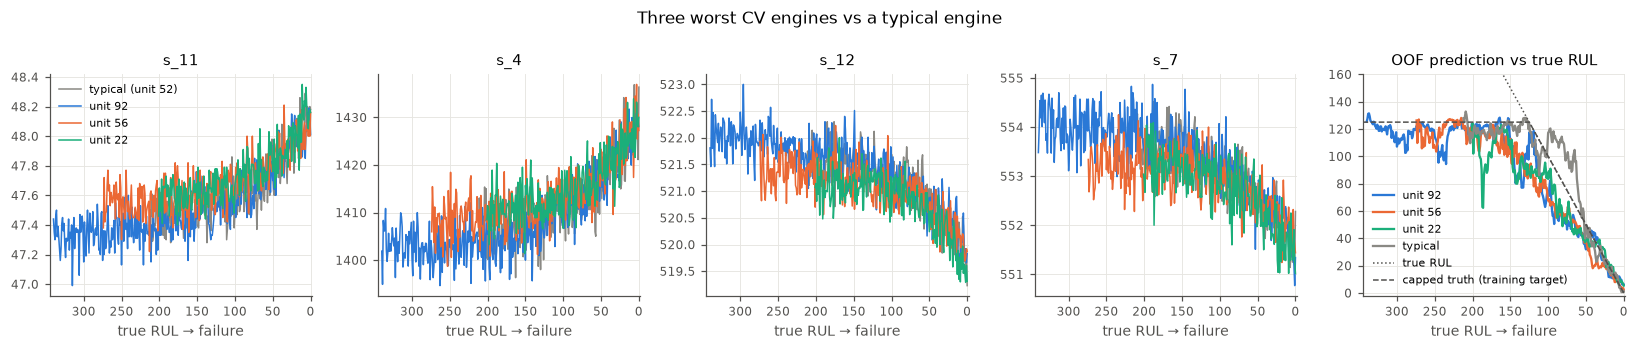

In [8]:
fig, axes = plt.subplots(1, len(KEY) + 1, figsize=(15, 3.2))
show = list(worst.index[:3])
x_max = train.loc[train["unit"].isin([*show, typical_unit]), "rul"].max() + 5
for ax, s in zip(axes, KEY, strict=False):
    g = train[train["unit"] == typical_unit]
    ax.plot(g["rul"], g[s], color=GRAY, linewidth=1, label=f"typical (unit {typical_unit})")
    for color, u in zip(SERIES, show, strict=True):
        g = train[train["unit"] == u]
        ax.plot(g["rul"], g[s], color=color, linewidth=1, label=f"unit {u}")
    ax.set_title(s)
    ax.set_xlim(x_max, -2)  # reversed: failure on the right
    ax.set_xlabel("true RUL → failure")
axp = axes[-1]
for color, u in zip(SERIES, show, strict=True):
    g = oof[oof["unit"] == u].sort_values("cycle")
    axp.plot(g["rul"], g["pred"], color=color, linewidth=1.5, label=f"unit {u}")
g = oof[oof["unit"] == typical_unit].sort_values("cycle")
axp.plot(g["rul"], g["pred"], color=GRAY, linewidth=1.5, label="typical")
ref = np.arange(0, x_max)
axp.plot(ref, ref, color=INK, linestyle=":", linewidth=1, label="true RUL")
axp.plot(
    ref,
    np.minimum(ref, DEFAULT_RUL_CAP),
    color=INK,
    linestyle="--",
    linewidth=1,
    label="capped truth (training target)",
)
axp.set_xlim(x_max, -2)
axp.set_ylim(-2, 160)
axp.set_title("OOF prediction vs true RUL")
axp.set_xlabel("true RUL → failure")
axp.legend(fontsize=7, frameon=False)
axes[0].legend(fontsize=7, frameon=False)
fig.suptitle("Three worst CV engines vs a typical engine", fontsize=11)
fig.tight_layout()
plt.show()

**Findings**

- **Per-engine errors have no extreme outliers.** Per-engine RMSE: median 15.6, 90th percentile 21.1, maximum 25.6.
- **4 of the 5 worst engines are long-lived and predicted early throughout:** units 92, 56, 22 and 86.
  - Their lifetimes are at the 57th to 99th percentile of the fleet.
  - Their bias is −11.3 to −17.7 on rows with true RUL ≤ 125.
  - It's −40.5 to −46.0 on rows with RUL > 125, about twice the fleet's −22.7 for that range.
  - So the cap explains only part of their error: they look more worn than they are even before the cap matters.
  - In the plot, their predictions fall below the capped truth between about RUL 125 and 60, while the typical engine (unit 52) sits above it.
- **Unit 57 is the opposite case:** it's among the shortest-lived engines (137 cycles, 3.5th percentile) and is **late**, with bias +19.1 on rows with RUL ≤ 125. That matches section 2.
- **Are they unusual? Partly.**
  - All sensor z-scores are within ±2.0.
  - Units **56 and 22** start life with sensor levels shifted in the *degradation* direction (`s_11` and `s_4` higher, `s_12` and `s_7` lower; |z| 1.1–2.0). That's consistent with higher initial wear making them look older than they are.
  - Units **92 and 86** show no such shift (|z| ≤ 0.5), so these four sensors don't explain their early bias.

## 4. Effect of the RUL cap

The model is trained on `min(RUL, 125)`, so it cannot learn to predict much above 125. For true
RUL above 125 it must under-predict: a structural, early (safe) bias. Here all OOF rows are used,
including those above 150 that are never scored.

In [9]:
bands = pd.cut(oof["rul"], [-1, 125, 150, 400], labels=["≤ 125", "126–150", "> 150"])
cap_table = oof.groupby(bands, observed=True).agg(
    rows=("error", "size"),
    rmse=("error", rmse),
    bias=("error", "mean"),
    mean_pred=("pred", "mean"),
    max_pred=("pred", "max"),
    mean_true=("rul", "mean"),
)
capped_err = oof["pred"] - np.minimum(oof["rul"], DEFAULT_RUL_CAP)
cap_table["rmse vs capped truth"] = capped_err.groupby(bands, observed=True).apply(rmse)
print(f"Largest OOF prediction anywhere: {oof['pred'].max():.1f} cycles\n")
cap_table

Largest OOF prediction anywhere: 133.6 cycles



,rows,rmse,bias,mean_pred,max_pred,mean_true,rmse vs capped truth
rul,,,,,,,
≤ 125,12600,14.23,3.77,66.27,131.06,62.50,14.23
126–150,2424,25.34,-22.74,115.12,131.11,137.86,13.60
> 150,5607,86.99,-77.50,119.13,133.63,196.63,9.31


In [10]:
s = scored.assign(sq=scored["error"] ** 2)
share = s.loc[s["rul"] > DEFAULT_RUL_CAP, "sq"].sum() / s["sq"].sum()
frac_rows = (s["rul"] > DEFAULT_RUL_CAP).mean()
print(
    f"Scored rows with true RUL > 125: {frac_rows:.1%} of rows, "
    f"{share:.1%} of the total squared error"
)
print(
    f"CV RMSE on scored rows: {rmse(s['error']):.2f}; "
    f"without the RUL > 125 rows: {rmse(s.loc[s['rul'] <= 125, 'error']):.2f}"
)

Scored rows with true RUL > 125: 16.1% of rows, 37.9% of the total squared error
CV RMSE on scored rows: 16.53; without the RUL > 125 rows: 14.23


**Findings**

- **The model cannot predict much above the cap.** The largest out-of-fold prediction anywhere is 133.6 cycles.
- **Rows with true RUL ≤ 125:** RMSE 14.23, bias +3.77.
- **Rows with true RUL 126–150:** RMSE 25.34, bias −22.74 (mean prediction 115.1 vs mean truth 137.9).
- **Rows with true RUL > 150** (never scored): RMSE 87.0, bias −77.5.
- **The model does predict its own target well.** Against the *capped* truth, the RMSE is only 13.60 for 126–150 and 9.31 for > 150. The large errors there are structural: they come from the cap, not from poor fitting.
- **The 126–150 rows are 16.1% of scored rows but 37.9% of the total squared error.** Excluding them, the pooled CV RMSE would drop from 16.53 to 14.23.
- **This error is early,** the safe direction. It's the price of the cap chosen in ADR 0001, which removed noise far from failure.

## 5. Test set (descriptive only)

The six largest test errors, described next to the CV patterns above. **Nothing here changes
the model.**

In [11]:
test_pred = pd.read_csv(PROJECT_ROOT / "reports" / "test_predictions_fd001.csv")
history = load_test("FD001").groupby("unit")["cycle"].max().rename("history")
test = test_pred.join(history, on="unit")
test["error"] = test["prediction"] - test["true_rul"]
test["covered"] = (test["lower"] <= test["true_rul"]) & (test["true_rul"] <= test["upper"])
print(
    f"Test engines: {len(test)}, RMSE {rmse(test['error']):.2f} (report: 14.59), "
    f"bias {test['error'].mean():.2f}, late share {(test['error'] > 0).mean():.0%}"
)
print(
    f"Test history length: min {test['history'].min()}, median {test['history'].median():.0f}, "
    f"max {test['history'].max()}"
)
top = test.reindex(test["error"].abs().sort_values(ascending=False).index).head(6)
top[["unit", "true_rul", "prediction", "error", "history", "lower", "upper", "covered"]]

Test engines: 100, RMSE 14.59 (report: 14.59), bias 2.05, late share 62%
Test history length: min 31, median 134, max 303


,unit,true_rul,prediction,error,history,lower,upper,covered
44,45,114,72.11,-41.89,152,43.33,100.89,False
66,67,77,109.25,32.25,71,76.06,142.45,True
92,93,85,54.16,-30.84,244,38.20,70.13,False
2,3,69,39.33,-29.67,126,23.36,55.30,False
49,50,79,108.31,29.31,74,75.12,141.51,True
24,25,145,116.85,-28.15,48,83.66,150.05,True


In [12]:
# CV context for each of the six: the CV bias and RMSE in the same (history, true-RUL) cell.
cell_bias = grid.mean()
cell_rmse = grid.apply(rmse)
rows = []
for _, r in top.iterrows():
    h = pd.cut([r["history"]], HIST)[0]
    b = pd.cut([r["true_rul"]], BANDS, include_lowest=True)[0]
    rows.append(
        {
            "unit": int(r["unit"]),
            "test error": r["error"],
            "history cell": str(h),
            "RUL band": str(b),
            "CV bias in cell": cell_bias.get((h, b), np.nan),
            "CV RMSE in cell": cell_rmse.get((h, b), np.nan),
            "true RUL > 125": r["true_rul"] > DEFAULT_RUL_CAP,
        }
    )
pd.DataFrame(rows).round(1)

,unit,test error,history cell,RUL band,CV bias in cell,CV RMSE in cell,true RUL > 125
0,45,-41.9,"(150, 400]","(100.0, 150.0]",-20.9,25.1,False
1,67,32.3,"(60, 100]","(50.0, 100.0]",19.9,23.8,False
2,93,-30.8,"(150, 400]","(50.0, 100.0]",-3.2,14.1,False
3,3,-29.7,"(100, 150]","(50.0, 100.0]",9.7,17.6,False
4,50,29.3,"(60, 100]","(50.0, 100.0]",19.9,23.8,False
5,25,-28.1,"(30, 60]","(100.0, 150.0]",-12.4,20.1,True


**Findings**

Descriptive only; nothing here changes the model.

- **The test set reproduces the report:** RMSE 14.59, bias +2.05, 62% of engines predicted late. Histories range from 31 to 303 cycles (median 134).
- **The six largest absolute errors** are 41.9, 32.3, 30.8, 29.7, 29.3 and 28.1 cycles.
- **Units 67 and 50 are late** (+32.3, +29.3). Their true RUL is 77–79 and they have only 71–74 cycles of history. That's exactly the CV pattern from section 2: CV bias +19.9 in the same cell. Both true values are still inside their intervals.
- **Unit 25 is early** (−28.1), with a true RUL of 145, above the cap. That's the structural cap effect from section 4.
- **Unit 45 is early** (−41.9), with true RUL 114 and 152 cycles of history. That's the same direction as the CV cell (bias −20.9) and the long-lived early pattern of section 3, but about twice as large.
- **Units 93 and 3 are early by about 30 cycles,** where their CV cells show a bias of −3.2 and +9.7. The CV patterns **do not explain** these two.
- **3 of the 6 fall outside their 90% interval** (units 45, 93 and 3), all on the early, safe side.

## 6. Summary: known weaknesses and possible remedies (future work, not applied)

These are documented for future work. **None is applied now:** each would need its own CV experiment and ADR. Because the FD001 test set has already been used, a changed model could not be honestly re-scored on it.

| Weakness (evidence above) | Possible remedy |
|---|---|
| **Late (dangerous) errors in mid-life:** true RUL 50–100, bias about +9, 26–27% of rows late by > 20 cycles (section 1) | An asymmetric loss that penalises late errors more, e.g. PHM08-weighted or a lower-quantile objective; or base maintenance decisions on the lower interval bound |
| **Short-lived, fast-degrading engines predicted late:** for a fixed RUL, short history means bias up to +20 (sections 2–3, unit 57; test units 67 and 50) | Features that measure each engine's degradation *rate*, e.g. longer windows, or change relative to the engine's own first cycles |
| **Engines with higher initial wear predicted early** (units 56 and 22) | Normalise each engine's sensors by its own early-life baseline |
| **Structural early bias above the cap:** RUL 126–150 is 37.9% of the squared error (section 4) | Inherent to the cap. Alternatives: report "RUL > 125" as a category rather than a number, or a higher cap with features that see further ahead |
| **Some large errors are unexplained** (units 92 and 86 in CV; test units 93 and 3) | Look at sensors beyond the four used here; collect more engines. With 100 engines, per-engine patterns are uncertain |

All of this applies to FD001 only.